# HD-PROCOVA Results

Visualize cross-validation and final model results from the HBM + ML pipeline on simulated data.

**Prerequisites:** Run these first:
```bash
python scripts/generate_data.py
python scripts/train_cv.py 1        # at least one fold
python scripts/train_final.py       # optional: final model
```

In [9]:
import sys
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import r2_score, mean_squared_error

PROJECT_ROOT = (Path.cwd() / '..').resolve()
RESULTS_DIR = PROJECT_ROOT / 'outputs' / 'training'
FINAL_DIR = PROJECT_ROOT / 'outputs' / 'final'

plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (10, 6)

## 1. Load cross-validation results

In [10]:
FOLD_RE = re.compile(r'results_fold_(\d+)\.csv$')
EXCLUDE = {'hbm', 'deployment'}

frames = []
for fp in sorted(RESULTS_DIR.glob('**/results_fold_*.csv')):
    model = fp.parent.name
    if model in EXCLUDE:
        continue
    fold = int(FOLD_RE.search(fp.name).group(1))
    df = pd.read_csv(fp)
    df['model'] = model
    df['fold'] = fold
    frames.append(df)

if frames:
    cv_df = pd.concat(frames, ignore_index=True)
    print(f'Loaded {len(frames)} fold files | {len(cv_df)} rows')
    print(f'Models: {sorted(cv_df["model"].unique())}')
else:
    print('No CV results found. Run: python scripts/train_cv.py 1')
    cv_df = None

Loaded 723 fold files | 316033 rows
Models: ['decision_tree', 'elasticnet', 'histgradientboosting', 'lasso', 'lightgbm', 'random_forest', 'ridge', 'svr', 'xgboost']


## 2. Model performance comparison

In [11]:
if cv_df is not None:
    metrics = []
    for (model, fold), g in cv_df.groupby(['model', 'fold']):
        if len(g) > 1:
            r2 = r2_score(g['actual_change'], g['predicted_change'])
            rmse = np.sqrt(mean_squared_error(g['actual_change'], g['predicted_change']))
            corr = np.corrcoef(g['actual_change'], g['predicted_change'])[0, 1]
            metrics.append({'model': model, 'fold': fold, 'R2': r2, 'RMSE': rmse, 'Corr': corr})

    metrics_df = pd.DataFrame(metrics)
    summary = metrics_df.groupby('model')[['R2', 'RMSE', 'Corr']].agg(['mean', 'std'])
    summary.columns = [f'{m}_{s}' for m, s in summary.columns]
    print(summary.sort_values('R2_mean', ascending=False).to_string())

                       R2_mean    R2_std  RMSE_mean  RMSE_std  Corr_mean  Corr_std
model                                                                             
lasso                 0.182861  0.114862   5.123623  0.531750   0.458099  0.119533
elasticnet            0.179632  0.108279   5.137612  0.541830   0.456518  0.119500
svr                   0.163090  0.107729   5.189376  0.544869   0.429539  0.115141
ridge                 0.139656  0.175085   5.236396  0.597091   0.446367  0.120206
xgboost               0.087215  0.124307   5.408355  0.568156   0.338177  0.136757
histgradientboosting  0.069334  0.120138   5.460694  0.552130   0.322773  0.130702
random_forest         0.068152  0.052747   5.482426  0.565013   0.343448  0.133613
lightgbm              0.064501  0.114882   5.481804  0.607682   0.312414  0.128388
decision_tree        -0.099866  0.098715   5.958569  0.599379  -0.022035  0.149099


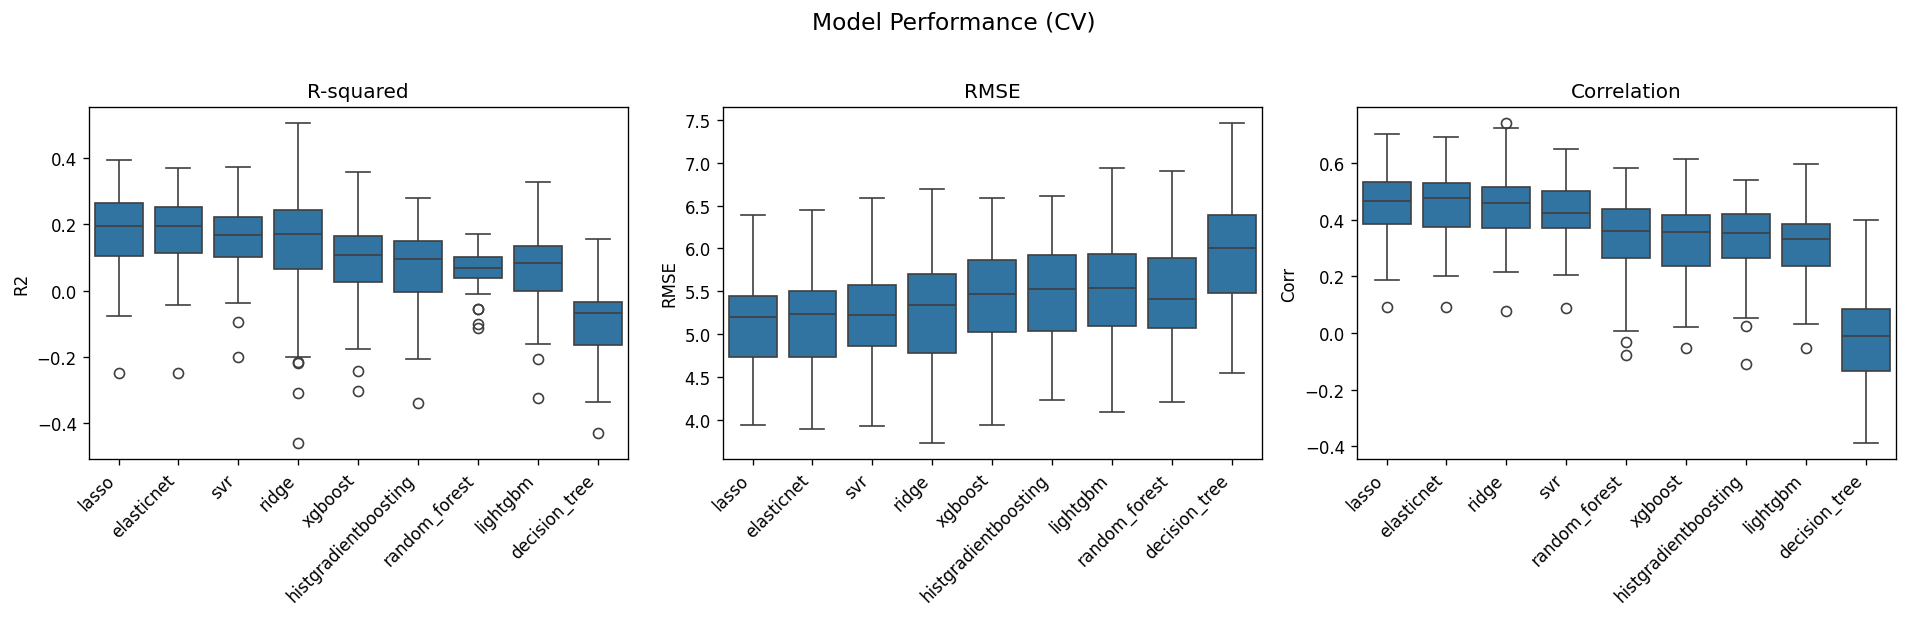

In [12]:
if cv_df is not None and len(metrics_df) > 0:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    for ax, metric, label in zip(axes, ['R2', 'RMSE', 'Corr'], ['R-squared', 'RMSE', 'Correlation']):
        order = metrics_df.groupby('model')[metric].mean().sort_values(ascending=(metric == 'RMSE')).index
        sns.boxplot(data=metrics_df, x='model', y=metric, order=order, ax=ax)
        ax.set_title(label)
        ax.set_xlabel('')
        ax.tick_params(axis='x', rotation=45)
        for tick in ax.get_xticklabels():
            tick.set_ha('right')

    fig.suptitle('Model Performance (CV)', fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

## 3. Predicted vs actual change

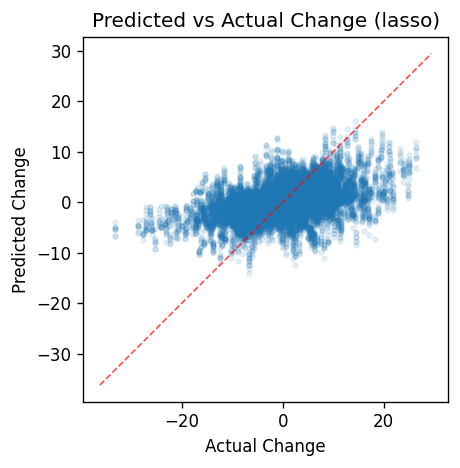

In [17]:
if cv_df is not None:
    best_model = metrics_df.groupby('model')['R2'].mean().idxmax()
    plot_df = cv_df[cv_df['model'] == best_model]

    fig, ax = plt.subplots(figsize=(4, 4))
    ax.scatter(plot_df['actual_change'], plot_df['predicted_change'], alpha=0.1, s=8)
    lims = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
    ax.plot(lims, lims, 'r--', lw=1, alpha=0.7)
    ax.set_xlabel('Actual Change')
    ax.set_ylabel('Predicted Change')
    ax.set_title(f'Predicted vs Actual Change ({best_model})')
    ax.set_aspect('equal')
    plt.tight_layout()
    plt.show()

## 4. Feature importance

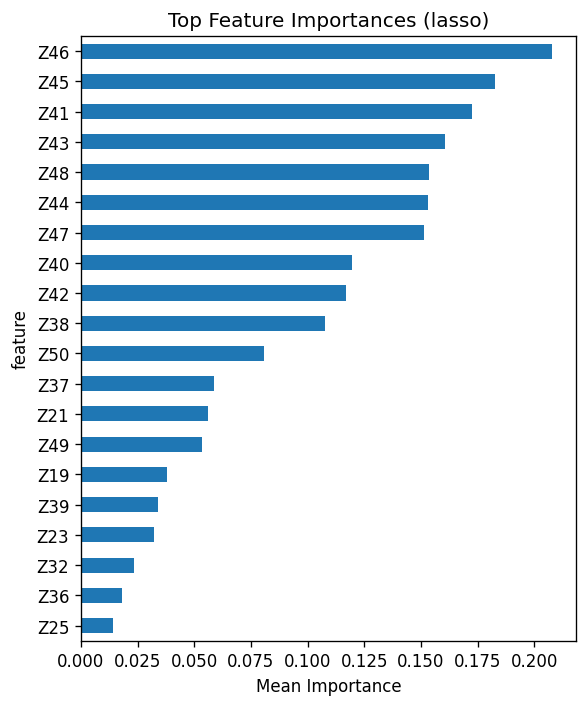

In [22]:
imp_frames = []
for fp in sorted(RESULTS_DIR.glob('**/importance_fold_*.csv')):
    model = fp.parent.name
    if model in EXCLUDE:
        continue
    fold = int(re.search(r'fold_(\d+)', fp.name).group(1))
    tmp = pd.read_csv(fp)
    tmp['model'] = model
    tmp['fold'] = fold
    imp_frames.append(tmp)

if imp_frames:
    imp_df = pd.concat(imp_frames, ignore_index=True)

    # Show mean importance for the best model
    if cv_df is not None:
        best_imp = imp_df[imp_df['model'] == best_model]
        mean_imp = best_imp.groupby('feature')['importance_mean'].mean().sort_values()

        fig, ax = plt.subplots(figsize=(5, 6))
        mean_imp.tail(20).plot.barh(ax=ax)
        ax.set_title(f'Top Feature Importances ({best_model})')
        ax.set_xlabel('Mean Importance')
        plt.tight_layout()
        plt.show()
else:
    print('No importance files found.')

## 5. Final model results

In [15]:
final_frames = []
if FINAL_DIR.exists():
    for fp in sorted(FINAL_DIR.glob('*/predictions.csv')):
        model = fp.parent.name
        if model in EXCLUDE:
            continue
        tmp = pd.read_csv(fp)
        tmp['model'] = model
        final_frames.append(tmp)

if final_frames:
    final_df = pd.concat(final_frames, ignore_index=True)
    print(f'Loaded {len(final_frames)} final model predictions')

    final_metrics = []
    for model, g in final_df.groupby('model'):
        if 'actual_change' in g.columns and len(g) > 1:
            r2 = r2_score(g['actual_change'], g['predicted_change'])
            rmse = np.sqrt(mean_squared_error(g['actual_change'], g['predicted_change']))
            corr = np.corrcoef(g['actual_change'], g['predicted_change'])[0, 1]
            final_metrics.append({'model': model, 'R2': r2, 'RMSE': rmse, 'Corr': corr})

    if final_metrics:
        fm_df = pd.DataFrame(final_metrics).set_index('model').sort_values('R2', ascending=False)
        print(fm_df.to_string())
else:
    print('No final model results. Run: python scripts/train_final.py')

Loaded 9 final model predictions
                            R2      RMSE      Corr
model                                             
svr                   0.331828  4.316846  0.586914
lasso                 0.330726  4.320407  0.582710
elasticnet            0.329400  4.324682  0.584240
ridge                 0.304074  4.405590  0.573451
histgradientboosting  0.232295  4.627216  0.491489
xgboost               0.229743  4.634900  0.491964
lightgbm              0.225555  4.647484  0.493507
random_forest         0.154162  4.856980  0.501138
decision_tree         0.021665  5.223558  0.181083
